# Machine Learning Fundamentals
## Unit 02 — Model Validation

**Stage 2: Machine Learning | Beginner level | B2 English**  
**Business scenario:** Estimating Melbourne house prices  
**Environment:** Google Colab / Jupyter Notebook  
**Libraries:** Pandas, Matplotlib, scikit-learn

---

### The question we will answer

You trained a Decision Tree model to estimate house prices. Its predictions looked excellent on the same houses used for training. Can we trust that result?

In this lesson, you will learn why evaluating a model on its training data can be misleading, how to create a separate validation set, and how to use Mean Absolute Error (MAE) to estimate predictive performance on unseen examples.

### Dataset

This notebook uses the supplied `melb_data.csv` file. It contains historical Melbourne property records. The target is `Price`, and the first model uses five numeric features: `Rooms`, `Bathroom`, `Landsize`, `Lattitude`, and `Longtitude`.

> **Instructor note:** This lesson is about evaluation, not about finding the best possible house-price model. Treat the result as a baseline and do not present it as a reliable current property valuation.

## Learning outcomes

By the end of this lesson, you should be able to:

1. Explain why a model must be evaluated on data not used for fitting.
2. Calculate and interpret Mean Absolute Error (MAE).
3. Distinguish training performance from validation performance.
4. Split features and targets with `train_test_split`.
5. Compare training and validation errors using a consistent model setup.
6. Explain the purpose of `random_state`.
7. Identify why a large gap between training and validation scores may indicate overfitting.

## Lesson roadmap

1. What is model validation?
2. Understand MAE
3. Load and prepare the dataset
4. See the problem with in-sample evaluation
5. Create a validation set
6. Compare and interpret results
7. Practice and readiness check

**Learning routine:** Read the explanation, run the code, inspect the output, and answer the question before moving on.

# 1. What Is Model Validation?

A Machine Learning model learns patterns from examples. After training, we need to estimate how well it will predict outcomes for examples it has not seen before.

**Model validation** means evaluating a model on data that was not used to fit it, so we can estimate how well its predictions may generalize to new cases.

For a house-price model, we compare predicted prices with known prices for houses held aside from training. We need a metric that summarizes many individual prediction errors into a value we can understand.

## 1.1 Understand Mean Absolute Error (MAE)

For each property:

\[
\text{Error} = \text{Actual Price} - \text{Predicted Price}
\]

MAE takes the absolute value of each error and calculates the average:

\[
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
\]

- \(y_i\) is the actual price.
- \(\hat{y}_i\) is the predicted price.
- \(n\) is the number of evaluated properties.
- Absolute values make errors non-negative, so overestimates and underestimates do not cancel each other out.

**How to interpret it:** If MAE is AUD 50,000, the predictions differ from the actual prices by AUD 50,000 on average in absolute terms for the evaluated rows. Lower MAE is generally better when comparing models on the same target and evaluation data.

In [1]:
import pandas as pd
import numpy as np

# A small example before using the real dataset
actual_prices = np.array([300_000, 450_000, 600_000])
predicted_prices = np.array([320_000, 410_000, 650_000])

absolute_errors = np.abs(actual_prices - predicted_prices)
example_mae = absolute_errors.mean()

example_table = pd.DataFrame({
    "actual_price": actual_prices,
    "predicted_price": predicted_prices,
    "absolute_error": absolute_errors
})
display(example_table)
print(f"MAE: AUD {example_mae:,.0f}")

,actual_price,predicted_price,absolute_error
0,300000,320000,20000
1,450000,410000,40000
2,600000,650000,50000


MAE: AUD 36,667


**Check your understanding**

1. Why do we take the absolute value of each error?
2. If Model A has an MAE of AUD 25,000 and Model B has an MAE of AUD 40,000 on the same validation set, which has the lower average absolute error?
3. Does an MAE of AUD 25,000 mean every prediction is wrong by exactly AUD 25,000?

# 2. Load and Prepare the Melbourne Dataset

We will use the same dataset and feature selection as in Unit 01. Keeping the context consistent allows us to focus on the new concept: evaluation.

In Google Colab, upload `melb_data.csv` to the session first. If the file is in the same folder as the notebook, the path below will work.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

melbourne_file_path = "melb_data.csv"
melbourne_data = pd.read_csv(melbourne_file_path)

feature_names = ["Rooms", "Bathroom", "Landsize", "Lattitude", "Longtitude"]
target_name = "Price"
required_columns = feature_names + [target_name]

print("Dataset shape:", melbourne_data.shape)
display(melbourne_data.head())

Dataset shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 2.1 Select features and target

`X` contains the input features. `y` contains the target we want to predict. The rows in both must correspond to the same properties.

For this introductory lesson, we remove rows that have missing values in the selected features or target. This keeps the example focused on validation. In real projects, removing rows should be a deliberate decision because it can reduce the data available and may introduce bias.

In [3]:
model_data = melbourne_data[required_columns].dropna().copy()

X = model_data[feature_names]
y = model_data[target_name]

print(f"Rows available after handling missing selected values: {len(model_data):,}")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", int(X.isna().sum().sum()))
print("Missing values in y:", int(y.isna().sum()))

Rows available after handling missing selected values: 13,580
X shape: (13580, 5)
y shape: (13580,)
Missing values in X: 0
Missing values in y: 0


# 3. The Problem with In-Sample Evaluation

An **in-sample score** is calculated on the same rows used to train the model. This can make the model appear much better than it really is.

Imagine a student practices a set of questions and is then tested using the exact same questions. A high score may show that the student remembers the practice examples, but it does not prove that they can answer new questions.

A decision tree can create detailed rules that fit training examples very closely. If we evaluate it on those same examples, its errors may be extremely small. What matters is how well it predicts houses that were not used during training.

## 3.1 Train a model and evaluate it on the same rows

First, we deliberately use the wrong evaluation approach to see the problem. We fit a Decision Tree on all selected data, then calculate MAE on those same rows.

This is a teaching demonstration of **in-sample evaluation**, not the recommended way to report model performance.

In [4]:
in_sample_model = DecisionTreeRegressor(random_state=1)
in_sample_model.fit(X, y)

in_sample_predictions = in_sample_model.predict(X)
in_sample_mae = mean_absolute_error(y, in_sample_predictions)

print(f"In-sample MAE: AUD {in_sample_mae:,.2f}")

In-sample MAE: AUD 1,125.18


The score may be very small because the model is evaluated on examples it has already learned from. A small training error alone is not enough evidence that the model will predict new properties accurately.

**Important:** Exact values can vary with dataset versions and model settings. Focus on the evaluation method and the difference between training and unseen-data performance.

# 4. Create a Validation Set

We need to set aside some data before fitting the model.

| Dataset part | Purpose | Used to fit the model? |
|---|---|---|
| **Training set** | Teach the model patterns from examples | Yes |
| **Validation set** | Estimate performance on unseen examples and compare model choices | No |

The `train_test_split()` function separates `X` and `y` into corresponding training and validation portions. Here, we use 25% of the rows for validation and set `random_state=0` so the split is repeatable.

In [5]:
train_X, val_X, train_y, val_y = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0
)

print(f"Training rows: {len(train_X):,}")
print(f"Validation rows: {len(val_X):,}")
print("Training feature shape:", train_X.shape)
print("Validation feature shape:", val_X.shape)

Training rows: 10,185
Validation rows: 3,395
Training feature shape: (10185, 5)
Validation feature shape: (3395, 5)


## 4.1 Fit using training data only

The model must be fitted using only `train_X` and `train_y`. It must not see `val_y` during training.

We use the same type of Decision Tree as in the in-sample demonstration. This makes the comparison easier to interpret.

In [6]:
validation_model = DecisionTreeRegressor(random_state=1)
validation_model.fit(train_X, train_y)

# Training predictions help us inspect fit on examples the model learned from.
train_predictions = validation_model.predict(train_X)

# Validation predictions are generated for held-out examples.
val_predictions = validation_model.predict(val_X)

train_mae = mean_absolute_error(train_y, train_predictions)
val_mae = mean_absolute_error(val_y, val_predictions)

print(f"Training MAE:   AUD {train_mae:,.2f}")
print(f"Validation MAE: AUD {val_mae:,.2f}")

Training MAE:   AUD 887.21
Validation MAE: AUD 250,429.61


## 4.2 Compare the scores

The training MAE measures errors on the examples used to fit the model. The validation MAE measures errors on held-out examples.

A large gap—very low training MAE and much higher validation MAE—can be a warning sign that the model has learned patterns that do not generalize well. This is one common sign of **overfitting**, which will be explored in more detail later.

Do not compare scores from different splits or different target definitions as if they were directly equivalent.

In [7]:
score_comparison = pd.DataFrame({
    "dataset": ["Training", "Validation"],
    "MAE_AUD": [train_mae, val_mae],
    "number_of_rows": [len(train_y), len(val_y)]
})
display(score_comparison)

,dataset,MAE_AUD,number_of_rows
0,Training,887.206676,10185
1,Validation,250429.612764,3395


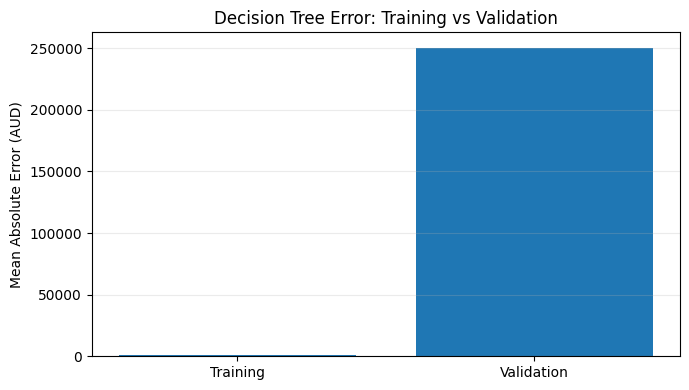

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(score_comparison["dataset"], score_comparison["MAE_AUD"])
ax.set_title("Decision Tree Error: Training vs Validation")
ax.set_ylabel("Mean Absolute Error (AUD)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4.3 What does `random_state` do?

`train_test_split()` randomly separates rows by default. Setting `random_state=0` makes the split repeatable, so the same rows are assigned to the training and validation sets each time you run the code with the same data and software behavior.

`random_state` does **not** automatically make a model more accurate. It supports reproducibility, which is important when teaching, debugging, and comparing experiments.

## 4.4 A simple baseline comparison

A model score is easier to interpret when compared with a simple baseline. For regression, one basic baseline predicts the median training target for every validation row.

If the Decision Tree does not improve on this simple baseline, it may not yet be providing useful predictive value. The baseline must be calculated from the training targets only.

In [ ]:
baseline_prediction_value = train_y.median()
baseline_predictions = np.full(shape=len(val_y), fill_value=baseline_prediction_value)
baseline_mae = mean_absolute_error(val_y, baseline_predictions)

baseline_comparison = pd.DataFrame({
    "model": ["Training-median baseline", "Decision Tree"],
    "validation_MAE_AUD": [baseline_mae, val_mae]
})
display(baseline_comparison)

**Interpret carefully:** The baseline comparison is a useful addition to the original lesson. It helps answer not only “How large is the error?” but also “Does this model improve on a simple prediction strategy?” It does not replace a broader evaluation plan.

# 5. Check Your Understanding

Answer these questions before completing the practical activity.

1. Why should validation data not be used to fit the model?
2. What does MAE measure, and what unit does it use here?
3. Why can the in-sample MAE be much smaller than validation MAE?
4. What might a large gap between training and validation MAE indicate?
5. What does `random_state=0` help us achieve?
6. Why is it useful to compare a model with a simple baseline?
7. Is one validation split enough to guarantee that the score will remain the same on every possible sample? Explain briefly.

# 6. Practical Activity — Model Validation

Complete the corresponding Kaggle lesson and exercise:

- [Kaggle — Model Validation lesson](https://www.kaggle.com/code/yazeedalasmar/notebook931b454bdd)


### Practice checklist

- [ ] Select the features and target.
- [ ] Split the data into training and validation sets.
- [ ] Fit the model using only training data.
- [ ] Generate predictions for the validation features.
- [ ] Calculate MAE using validation targets and predictions.
- [ ] Compare training and validation MAE.
- [ ] Compare the Decision Tree against the training-median baseline.
- [ ] Explain what the scores suggest and what they cannot prove.

### Mini-challenge

Change the `random_state` in `train_test_split()` from `0` to `42` and rerun the split and evaluation. Compare the scores. Explain why the values may change, and why you should not keep changing the split just to obtain a preferred score.